**#Data cleaning**





In [ ]:
#Telecom dataset https://www.kaggle.com/datasets/blastchar/telco-customer-churn?resource=download

In [ ]:
#Import Lib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Load dataset
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
#Dispaly first  rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
#Check Shape
df.shape

(7043, 21)

In [ ]:
#Display Column name
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
#Check Datatypes
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


**This is important because TotalCharges should eventually be converted into a numeric column it is now in object form**

In [ ]:
#Basic Statistics(count , mean std , min, (fq25%),(sq50%),(tq75% )
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
#Check Missing Values
df.isnull().sum()
#Tells the missing values in each column


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


**`Data cleaning according to the project requirement `**

In [ ]:
#check total charges
df['TotalCharges'].dtype
#O means object/string, but TotalCharges should be numeric.

dtype('O')

In [ ]:
#Convert TotalCharges to Numeric
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
#Some values in TotalCharges contain blank spaces. Using errors='coerce' converts those invalid values into NaN

In [ ]:
#now the total charges dtype is
df['TotalCharges'].dtype

dtype('float64')

In [ ]:
#Check the New Null Values
df['TotalCharges'].isnull().sum()

#So there are 11 missing values in TotalCharges after conversion.

np.int64(11)

In [ ]:
#verify missing values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
#Handle Missing Values
df = df.dropna(subset=['TotalCharges'])
#Why are we dropping them?

#The number of missing records is very small compared with the total dataset, and TotalCharges is an important numerical feature. Removing these few incomplete records avoids introducing artificial values through imputation.

In [ ]:
#check
df['TotalCharges'].isnull().sum()

np.int64(0)

In [ ]:
#check dataset shape again
df.shape

(7032, 21)

In [ ]:
#Drop custoner_id
#customerID is simply an identifier.
#It does not contain meaningful information that should be used to predict churn.
df = df.drop('customerID',axis=1)

In [ ]:
#verify
df.shape

(7032, 20)

In [ ]:
# convert churn to 0 and 1
#currently churn contains yes and no
#convert it in binary values
#0 = Customer did not churn
#1 = Customer churned
df['Churn'] = df['Churn'].map({
    'Yes':1,
    'No':0
})

In [ ]:
print("Missing Churn values:")
print(df['Churn'].isnull().sum())

print("\nChurn Values:")
print(df['Churn'].value_counts())

Missing Churn values:
0

Churn Values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [ ]:
#Verify the Cleaning
print("Shape:",df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("churn Values:")
print(df['Churn'].value_counts())

Shape: (7032, 20)

Data Types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
Mont

**#EDA**

#Churn Distribution
Objective First, we need to understand how many customers:
Churned → 1
Did not churn → 0
This also tells us whether the target variable is balanced or imbalanced.
Check the Churn Counts

In [ ]:

df['Churn'].value_counts()

,count
Churn,
0,5163
1,1869


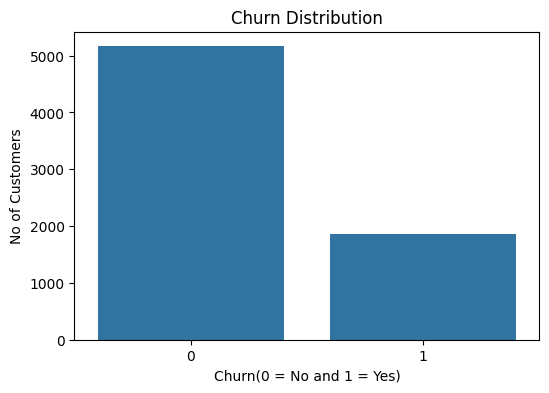

In [ ]:
#Create the Churn Distribution Plot
plt.figure(figsize=(6,4))
sns.countplot(x='Churn',data=df)

plt.title('Churn Distribution')
plt.xlabel('Churn(0 = No and 1 = Yes)')
plt.ylabel('No of Customers')
plt.show()
#This gives you a simple bar chart showing the number of churned and non-churned customers.

In [ ]:
#Add Percentage
churn_percentage = df['Churn'].value_counts(normalize=True)*100
print(churn_percentage)
#So approximately 26.6% of customers churned, while 73.4% did not churn.

Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64


Observation

**The dataset is imbalanced, with approximately 73.4% of customers not churning and 26.6% of customers churning. This shows that the number of non-churned customers is significantly higher than the number of churned customers. Therefore, accuracy alone may not be sufficient for evaluating the classification models, and metrics such as recall, F1-score, and ROC-AUC should also be considered. **

#Churn Rate by Contract Type
Now we analyze whether the type of contract is related to customer churn.

Your dataset has three contract types:

Month-to-month
One year
Two year

We should compare the churn rate, not just the number of customers.

In [ ]:
#Calculate Churn Rate by Contract
contract_churn_rate = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
)
print(contract_churn_rate)
#This calculates the percentage of customers
#within each contract type who churned or stayed.

Churn                  0         1
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887228  0.112772
Two year        0.971513  0.028487


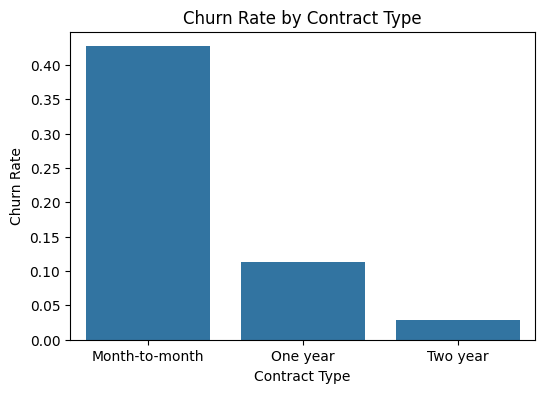

In [ ]:
#plot the Churn Rate
plt.figure(figsize=(6,4))
sns.barplot(x=contract_churn_rate.index,y=contract_churn_rate[1])
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate')
plt.show()


This graph shows month-to-month customers have the highest churn rate, while customers with two-year contracts have the lowest churn rate.

In [ ]:
#Display the Actual Percentages
for contract, rate in contract_churn_rate[1].items():
    print(f"{contract}: {rate:.2f}% churn rate")

Month-to-month: 0.43% churn rate
One year: 0.11% churn rate
Two year: 0.03% churn rate


Observation

The month-to-month contract has the highest churn rate, at approximately 43%, while one-year and two-year contracts have much lower churn rates. Customers with longer-term contracts are therefore considerably less likely to churn. This suggests that encouraging customers to move from month-to-month contracts to longer-term contracts could be an effective customer retention strategy.

Tenure Distribution — Churned vs Non-Churned

**Now we analyze how long customers have stayed with the company and whether tenure differs between customers who churned and those who stayed.**

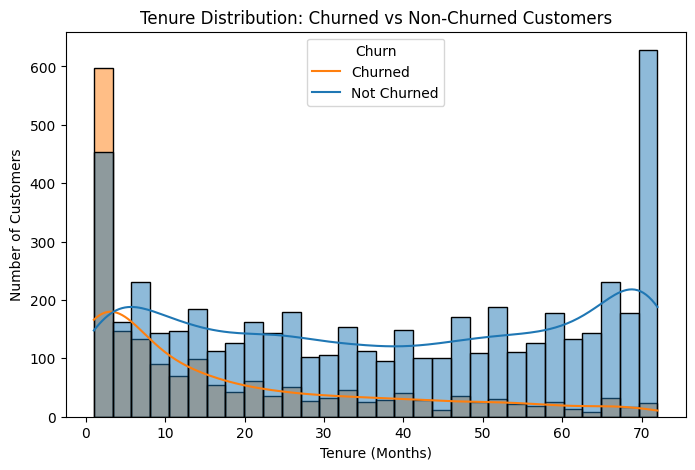

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True,
    multiple='layer'
)

plt.title('Tenure Distribution: Churned vs Non-Churned Customers')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['Churned', 'Not Churned'])

plt.show()

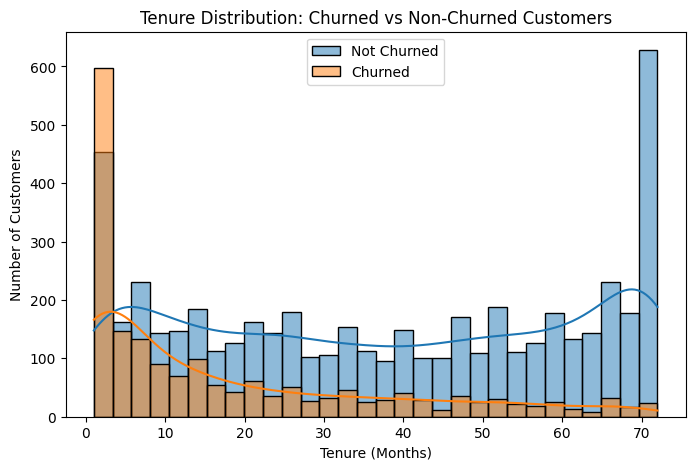

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df[df['Churn'] == 0],
    x='tenure',
    bins=30,
    kde=True,
    label='Not Churned',
    alpha=0.5
)

sns.histplot(
    data=df[df['Churn'] == 1],
    x='tenure',
    bins=30,
    kde=True,
    label='Churned',
    alpha=0.5
)

plt.title('Tenure Distribution: Churned vs Non-Churned Customers')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.legend()

plt.show()

#Compare Average *Tenure*

In [ ]:
df.groupby('Churn')['tenure'].mean()

,tenure
Churn,
0,37.650010
1,17.979133


You should see that customers who churned generally have a lower average tenure than customers who stayed.

In [ ]:
for churn, avg_tenure in df.groupby('Churn')['tenure'].mean().items():
    status = 'Churned' if churn == 1 else 'Not Churned'
    print(f"{status}: {avg_tenure:.2f} months")

Not Churned: 37.65 months
Churned: 17.98 months


#Observation

The tenure distribution shows that customers who churned generally have shorter tenure compared with customers who remained with the company. Churn is more common among relatively new customers, while customers with longer tenure tend to be more stable. This suggests that the company should pay particular attention to new customers and develop early-stage retention strategies.

#Monthly Charges Distribution — Churned vs Non-Churned

We want to see whether customers who churn have different monthly charges compared with customers who stay.

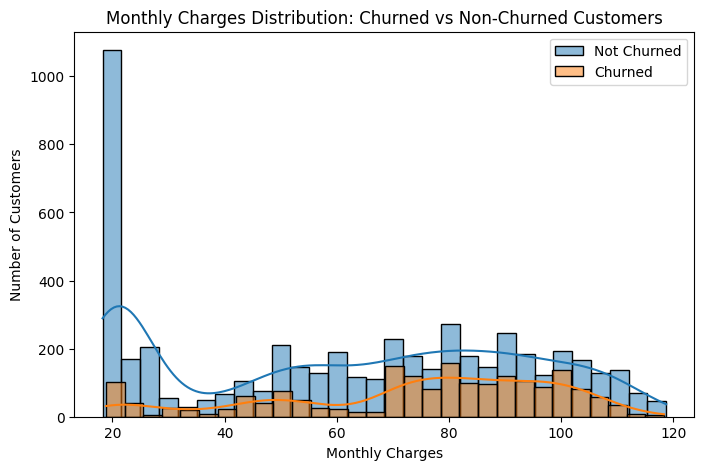

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df[df['Churn'] == 0],
    x='MonthlyCharges',
    bins=30,
    kde=True,
    label='Not Churned',
    alpha=0.5
)

sns.histplot(
    data=df[df['Churn'] == 1],
    x='MonthlyCharges',
    bins=30,
    kde=True,
    label='Churned',
    alpha=0.5
)

plt.title('Monthly Charges Distribution: Churned vs Non-Churned Customers')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.legend()

plt.show()

In [ ]:
df.groupby('Churn')['MonthlyCharges'].mean()

,MonthlyCharges
Churn,
0,61.307408
1,74.441332


In [ ]:
for churn, avg_charge in df.groupby('Churn')['MonthlyCharges'].mean().items():
    status = 'Churned' if churn == 1 else 'Not Churned'
    print(f"{status}: ${avg_charge:.2f}")

Not Churned: $61.31
Churned: $74.44



The distribution shows that churned customers generally have higher monthly charges compared with customers who did not churn. This indicates that customers paying higher monthly charges may have a greater likelihood of leaving the company. The company could therefore consider reviewing pricing and service packages for customers with relatively high monthly charges.

#Correlation Heatmap

We need to examine relationships between the numeric variables.

In [ ]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

In [ ]:
numeric_df.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn'], dtype='object')

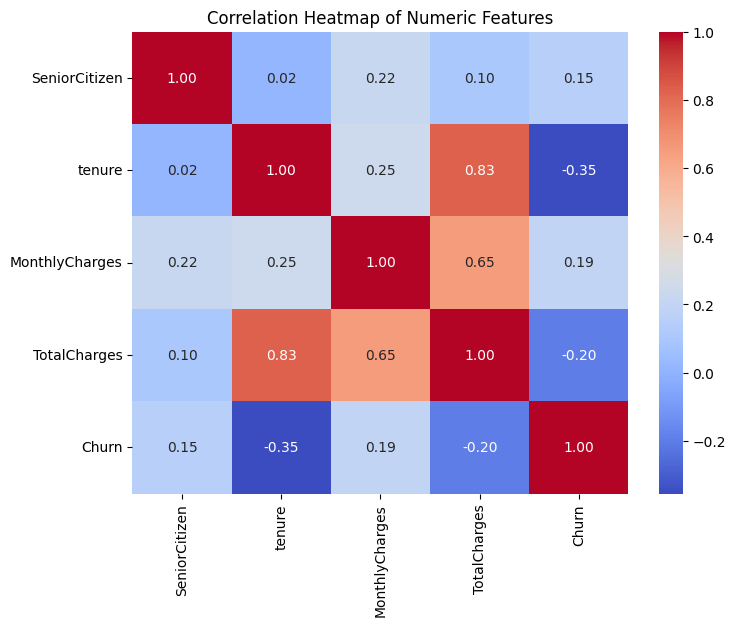

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numeric Features')

plt.show()

The correlation heatmap shows the relationships between the numeric variables in the dataset. Tenure and TotalCharges have a strong positive relationship because customers who stay longer generally accumulate higher total charges. Churn has relatively weaker linear correlations with the individual numeric variables, indicating that multiple customer characteristics should be considered together when predicting churn.

#Step 5 — Data Preprocessing

Step 5 has 4 main parts:

Identify categorical columns and encode them,
Separate X and y,
Perform an 80/20 train-test split,
Apply StandardScaler correctly.


In [ ]:
df.dtypes


,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [ ]:
#categorical columns
categorical_features = df.select_dtypes(
    include=['object']
).columns.tolist()

categorical_features

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [ ]:
#numeric columns
numeric_featurues = df.select_dtypes(
    include=['int64','float64']
).columns.tolist()

numeric_featurues

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']

#we remove the churn beacuse it is our target variable.

In [ ]:
numeric_features = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

In [ ]:
numeric_features

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

#5.2 Encode Categorical Variables

For this dataset, use One-Hot Encoding for the categorical variables.

Why One-Hot Encoding?

Most categorical variables are nominal, meaning their categories do not have a natural numerical order.

For example:

PaymentMethod:
Electronic check
Mailed check
Bank transfer
Credit card

Giving them numbers such as 1, 2, 3, 4 could incorrectly imply that one payment method is greater than another.

Therefore, one-hot encoding is appropriate.

In [ ]:
#Create the Encoding
df_encoded = pd.get_dummies(
    df,columns=categorical_features,
    drop_first=True,
    dtype='int'
)

In [ ]:
df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


You will now have more columns because categorical variables have been converted into binary dummy variables.

In [ ]:
df_encoded.shape

(7032, 31)

#5.3 Separate Features and Target

Now separate the input variables from the target variable.

In [ ]:
#feature x
X = df_encoded.drop('Churn',axis=1)

In [ ]:
y = df_encoded['Churn']

In [ ]:
#check
print("Shape:",X.shape)
print("y Shape:",y.shape)

Shape: (7032, 30)
y Shape: (7032,)


In [ ]:
print("X columns:")
print(X.columns)
#Important: Churn must not be present inside X.

X columns:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')


#5.4 Train-Test Split
Your instructions specifically require:

80% training
20% testing
random_state=42

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Why stratify=y?

Your churn data is imbalanced.

stratify=y ensures that the training and testing sets maintain approximately the same proportion of churned and non-churned customers.

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 30)
X_test: (1407, 30)
y_train: (5625,)
y_test: (1407,)


#5.5 Standard Scaling
identify these three columns for scaling:
tenure,
MonthlyCharges,
TotalCharges.


In [ ]:
numeric_features

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [ ]:
# Numerical columns that need Standard Scaling
scaling_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

scaling_features

['tenure', 'MonthlyCharges', 'TotalCharges']

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train[scaling_features] = scaler.fit_transform(X_train[scaling_features])
X_test[scaling_features] = scaler.transform(X_test[scaling_features])

In [ ]:
X_train[scaling_features].describe()

,tenure,MonthlyCharges,TotalCharges
count,5.625000e+03,5.625000e+03,5.625000e+03
mean,-1.291609e-16,3.157968e-17,8.842310e-18
std,1.000089e+00,1.000089e+00,1.000089e+00
min,-1.286145e+00,-1.547843e+00,-1.003365e+00
25%,-9.601500e-01,-9.698847e-01,-8.301191e-01
50%,-1.451620e-01,1.860324e-01,-3.918414e-01
75%,9.550717e-01,8.320837e-01,6.591681e-01
max,1.607062e+00,1.782062e+00,2.805224e+00


#Step 6 — Model Building

our assignment requires exactly these 5 models:

Logistic Regression
K-Nearest Neighbors (KNN)
Decision Tree Classifier
Random Forest Classifier
Support Vector Machine (SVM)

In [ ]:
#Import all 5 models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

#6.2.1 Logistic Regression

In [ ]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

In [ ]:
#prediction
y_pred_logistic[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 1, 0])

#6.3.1 K-Nearest Neighbors (KNN)

In [ ]:
knn_model = KNeighborsClassifier()

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

In [ ]:
y_pred_knn[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 1, 0])

#6.4.1 Decision Tree Classifier

In [ ]:
decision_tree_model = DecisionTreeClassifier(random_state=42)

decision_tree_model.fit(X_train, y_train)

y_pred_tree = decision_tree_model.predict(X_test)

In [ ]:
y_pred_tree[:10]

array([0, 1, 0, 0, 0, 1, 0, 0, 1, 0])

#6.5.1 Random Forest Classifier

In [ ]:
random_forest_model = RandomForestClassifier(random_state=42)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

In [ ]:
y_pred_rf[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 1, 0])

#6.6.1 Support Vector Machine (SVM)
For the SVM, we need the model's probability later for ROC-AUC.

Therefore, use probability=True.

In [ ]:
svm_model = SVC(probability=True, random_state=42)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

In [ ]:
y_pred_svm[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 1, 0])

#6.7 Store All Models Together
Model Evaluation

In [ ]:
models = {
    'Logistic Regression': logistic_model,
    'K-Nearest Neighbors': knn_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'Support Vector Machine': svm_model
}

In [ ]:
#predictions
predictions = {
    'Logistic Regression': y_pred_logistic,
    'K-Nearest Neighbors': y_pred_knn,
    'Decision Tree': y_pred_tree,
    'Random Forest': y_pred_rf,
    'Support Vector Machine': y_pred_svm
}

In [ ]:
predictions.keys()

dict_keys(['Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree', 'Random Forest', 'Support Vector Machine'])

#Step 7 — Model Evaluation and Comparison
Assignment requires:

Accuracy
Precision
Recall
F1-Score
Confusion Matrix as a Seaborn heatmap
ROC-AUC
Final comparison table

#7.1 Import Evaluation Metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

#7.2 Calculate Accuracy, Precision, Recall and F1-Score

In [ ]:
results = []

for model_name, model in models.items():

    y_pred = predictions[model_name]

    accuracy = accuracy_score(y_test, y_pred)

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True
    )

    precision = report['1']['precision']
    recall = report['1']['recall']
    f1 = report['1']['f1-score']

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

results

[{'Model': 'Logistic Regression',
  'Accuracy': 0.8045486851457001,
  'Precision': 0.6504559270516718,
  'Recall': 0.5721925133689839,
  'F1-Score': 0.6088193456614509},
 {'Model': 'K-Nearest Neighbors',
  'Accuracy': 0.7619047619047619,
  'Precision': 0.549618320610687,
  'Recall': 0.5775401069518716,
  'F1-Score': 0.5632333767926988},
 {'Model': 'Decision Tree',
  'Accuracy': 0.7164179104477612,
  'Precision': 0.46612466124661245,
  'Recall': 0.45989304812834225,
  'F1-Score': 0.4629878869448183},
 {'Model': 'Random Forest',
  'Accuracy': 0.7882018479033405,
  'Precision': 0.6233766233766234,
  'Recall': 0.5133689839572193,
  'F1-Score': 0.5630498533724341},
 {'Model': 'Support Vector Machine',
  'Accuracy': 0.7931769722814499,
  'Precision': 0.6487455197132617,
  'Recall': 0.4839572192513369,
  'F1-Score': 0.554364471669219}]

#7.3 Calculate ROC-AUC

In [ ]:
roc_auc_results = {}

for model_name, model in models.items():

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    roc_auc = roc_auc_score(y_test, y_score)

    roc_auc_results[model_name] = roc_auc

roc_auc_results

{'Logistic Regression': np.float64(0.8360714082341553),
 'K-Nearest Neighbors': np.float64(0.7859085991168446),
 'Decision Tree': np.float64(0.6343317578725586),
 'Random Forest': np.float64(0.8156283810716929),
 'Support Vector Machine': np.float64(0.7833021002117294)}

Because we used:

SVC(probability=True)

SVM also provides probabilities.

#7.4 Add ROC-AUC to the Results

In [ ]:
for result in results:
    result['ROC-AUC'] = roc_auc_results[result['Model']]

In [ ]:
results_df = pd.DataFrame(results)

In [ ]:
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.804549,0.650456,0.572193,0.608819,0.836071
1,K-Nearest Neighbors,0.761905,0.549618,0.577540,0.563233,0.785909
2,Decision Tree,0.716418,0.466125,0.459893,0.462988,0.634332
3,Random Forest,0.788202,0.623377,0.513369,0.563050,0.815628
4,Support Vector Machine,0.793177,0.648746,0.483957,0.554364,0.783302


#7.5 Format the Comparison Table

In [ ]:
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8045,0.6505,0.5722,0.6088,0.8361
1,K-Nearest Neighbors,0.7619,0.5496,0.5775,0.5632,0.7859
2,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343
3,Random Forest,0.7882,0.6234,0.5134,0.5630,0.8156
4,Support Vector Machine,0.7932,0.6487,0.4840,0.5544,0.7833


In [ ]:
results_df.sort_values(
    by='F1-Score',
    ascending=False
).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8045,0.6505,0.5722,0.6088,0.8361
1,K-Nearest Neighbors,0.7619,0.5496,0.5775,0.5632,0.7859
3,Random Forest,0.7882,0.6234,0.5134,0.5630,0.8156
4,Support Vector Machine,0.7932,0.6487,0.4840,0.5544,0.7833
2,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343


In [ ]:
#7.6 Display Classification Reports
for model_name, model in models.items():

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[model_name]
        )
    )

Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

K-Nearest Neighbors
              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1033
           1       0.55      0.58      0.56       374

    accuracy                           0.76      1407
   macro avg       0.70      0.70      0.70      1407
weighted avg       0.77      0.76      0.76      1407

Decision Tree
              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1033
           1       0.47      0.46      0.46       374

    accuracy                           0.72      1407
   macro avg       0.64      0.63      0.64      1407
weighted avg       0

#7.7 Confusion Matrix — All Five Models
Confusion Matrix displayed as a heatmap using seaborn.

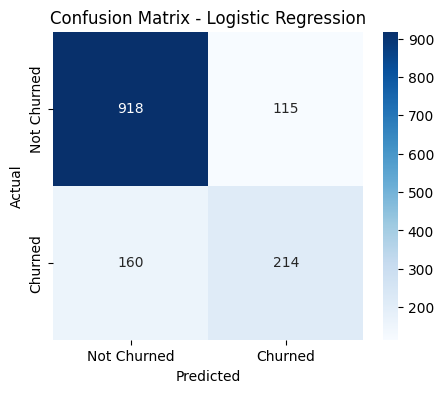

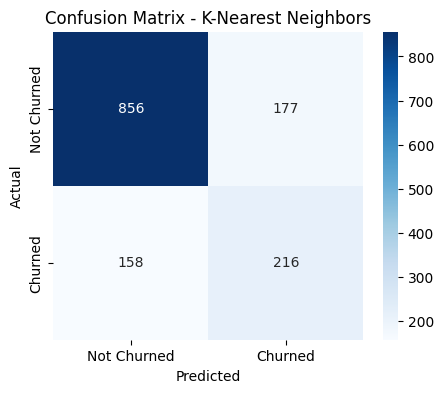

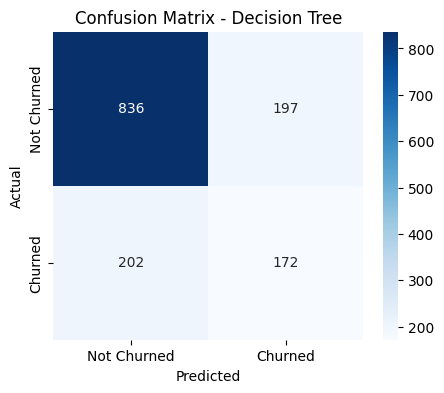

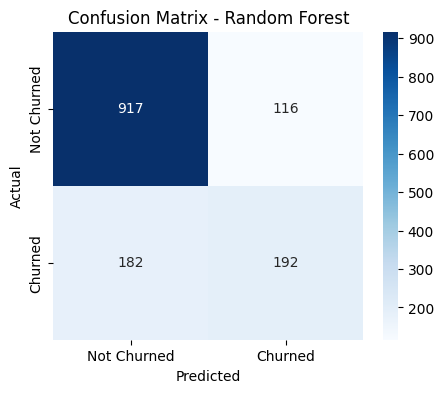

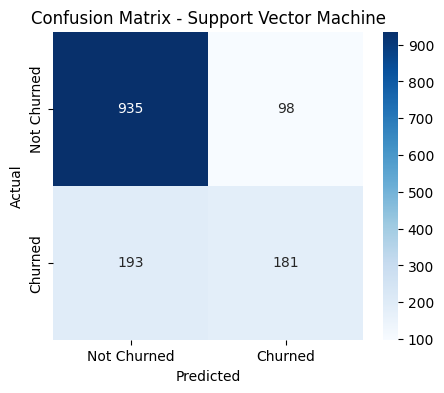

In [ ]:
for model_name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Churned', 'Churned'],
        yticklabels=['Not Churned', 'Churned']
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()

#7.8 Understand the Confusion Matrix
The matrix will look like:

                  Predicted
                0          1

Actual  0      TN         FP
        1      FN         TP

For churn prediction:

TN → Customer stayed and model predicted stayed.
FP → Customer stayed but model predicted churn.
FN → Customer churned but model predicted stayed.
TP → Customer churned and model correctly predicted churn.
Most important business case

False Negative (FN) is particularly important.

That means:

The customer actually churned, but the model failed to identify them.

The company loses the opportunity to intervene.

This is why Recall for the churn class matters significantly.

#7.9 Final Comparison Table

In [ ]:
final_comparison = results_df[
    [
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC'
    ]
].copy()

final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8045,0.6505,0.5722,0.6088,0.8361
1,K-Nearest Neighbors,0.7619,0.5496,0.5775,0.5632,0.7859
2,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343
3,Random Forest,0.7882,0.6234,0.5134,0.5630,0.8156
4,Support Vector Machine,0.7932,0.6487,0.4840,0.5544,0.7833


#7.10 Find the Best Model

In [ ]:
best_model_row = final_comparison.loc[
    final_comparison['F1-Score'].idxmax()
]

best_model_row

,0
Model,Logistic Regression
Accuracy,0.804549
Precision,0.650456
Recall,0.572193
F1-Score,0.608819
ROC-AUC,0.836071


#Step 8 — Best Model Selection and Business Recommendation

8.1 Display the comparison

In [ ]:
final_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8045,0.6505,0.5722,0.6088,0.8361
1,K-Nearest Neighbors,0.7619,0.5496,0.5775,0.5632,0.7859
2,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343
3,Random Forest,0.7882,0.6234,0.5134,0.5630,0.8156
4,Support Vector Machine,0.7932,0.6487,0.4840,0.5544,0.7833


#8.2 Identify the best model

Since this is a churn problem, we should prioritize Recall and F1-Score, with ROC-AUC as an additional measure rather than simply choosing the highest accuracy.

In [ ]:
# Sort models by Recall, F1-Score, and ROC-AUC
model_ranking = final_comparison.sort_values(
    by=['Recall', 'F1-Score', 'ROC-AUC'],
    ascending=False
)

model_ranking.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,K-Nearest Neighbors,0.7619,0.5496,0.5775,0.5632,0.7859
0,Logistic Regression,0.8045,0.6505,0.5722,0.6088,0.8361
3,Random Forest,0.7882,0.6234,0.5134,0.5630,0.8156
4,Support Vector Machine,0.7932,0.6487,0.4840,0.5544,0.7833
2,Decision Tree,0.7164,0.4661,0.4599,0.4630,0.6343


In [ ]:
best_model_name = model_ranking.iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: K-Nearest Neighbors


#8.3 Display the selected model's actual results

In [ ]:
best_model_results = final_comparison[
    final_comparison['Model'] == best_model_name
]

best_model_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,K-Nearest Neighbors,0.7619,0.5496,0.5775,0.5632,0.7859


#8.4 — Best Model Selection and Justification

## 8.4 Best Model Selection and Justification

Based on the comparison of the five classification models, **K-Nearest Neighbors (KNN)** is selected as the best-performing model for this project. KNN achieved an accuracy of **76.19%**, precision of **54.96%**, recall of **57.75%**, F1-score of **56.32%**, and ROC-AUC of **78.59%**. The model is not selected based on accuracy alone because identifying customers who are likely to churn is the main business objective. Recall is important because a false negative represents a customer who actually churns but is not identified by the model, resulting in a missed opportunity for customer retention. The F1-score provides a balance between precision and recall, while the ROC-AUC indicates the model's ability to distinguish between churned and non-churned customers.


#8.5 — Business Recommendation

## 8.5 Business Recommendation

The telecom company should use the **K-Nearest Neighbors (KNN)** model to identify customers who are more likely to churn. Customers predicted as high-risk should be prioritized for proactive retention campaigns before they leave the company. The EDA showed that month-to-month customers have a substantially higher churn rate than customers with one-year or two-year contracts, so the company should encourage month-to-month customers to choose longer-term contracts through suitable incentives. Customers with shorter tenure should also receive additional engagement and support during the early stages of their relationship. Customers with relatively high monthly charges can be offered personalized plans or suitable discounts. By combining KNN predictions with these customer insights, the company can focus its retention resources on customers most likely to churn and reduce customer loss.


#8.6 — Final Step 8 Verification

In [ ]:
print("Selected Best Model:", best_model_name)

print("\nPerformance Metrics:")
print(best_model_results.round(4))

Selected Best Model: K-Nearest Neighbors

Performance Metrics:
                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
1  K-Nearest Neighbors    0.7619     0.5496  0.5775    0.5632   0.7859


## 8.6 Final Conclusion

The customer churn analysis successfully developed and evaluated five classification models for predicting telecom customer churn. Based on the model comparison, K-Nearest Neighbors (KNN) was selected as the best-performing model according to the evaluation criteria used in this project. The model achieved a ROC-AUC of 78.59% and a recall of 57.75%, providing a useful ability to identify customers who may churn. The results from the EDA also provide useful business insights into contract type, tenure, and monthly charges. These insights can be combined with the model predictions to support targeted customer retention strategies. The company can use the model to prioritize high-risk customers and take proactive actions to improve customer retention.


#Step 9 — Dashboard

8-section ML assignment is complete. Now we can build the dashboard using the results from your notebook.

#9.1 Prepare KNN Predictions

In [ ]:
# Generate predictions using the selected KNN model
knn_predictions = knn_model.predict(X_test)

# Generate churn probabilities
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]

print("Number of predictions:", len(knn_predictions))
print("Number of probabilities:", len(knn_probabilities))

Number of predictions: 1407
Number of probabilities: 1407


#9.2 Create Dashboard Prediction Data
Because you dropped customerID during cleaning, we no longer have the original customer IDs in the modeling data. So we'll create a Customer_Index for dashboard identification.


In [ ]:
dashboard_df = X_test.copy()

dashboard_df['Actual_Churn'] = y_test.values
dashboard_df['Predicted_Churn'] = knn_predictions
dashboard_df['Churn_Probability'] = knn_probabilities


In [ ]:
dashboard_df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Actual_Churn,Predicted_Churn,Churn_Probability
974,0,1.077320,0.363738,0.984674,0,1,1,1,0,0,...,1,0,1,1,1,0,0,0,0,0.0
619,0,-1.041649,0.450100,-0.781798,0,0,0,1,0,1,...,0,0,0,1,0,0,0,0,1,0.8
4289,0,0.873573,-1.491376,-0.537223,0,0,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0.0
3721,0,-1.245396,-1.473107,-0.994619,0,0,0,1,0,0,...,0,0,0,0,0,0,1,1,0,0.2
4533,0,1.566313,1.333645,2.308692,0,1,0,1,0,1,...,1,0,1,1,0,0,0,0,0,0.0


#9.3 Create Risk Category

Now classify customers according to their predicted churn probability.

We'll use:

Below 30% → Low Risk
30%–70% → Medium Risk
Above 70% → High Risk

In [ ]:
def risk_category(probability):
    if probability < 0.30:
        return 'Low Risk'
    elif probability <= 0.70:
        return 'Medium Risk'
    else:
        return 'High Risk'


dashboard_df['Risk_Category'] = dashboard_df[
    'Churn_Probability'
].apply(risk_category)

In [ ]:
dashboard_df['Risk_Category'].value_counts()

,count
Risk_Category,
Low Risk,825
Medium Risk,397
High Risk,185


#9.4 Add Customer Index
Since customerID was removed according to assignment, we'll create an index only for dashboard purposes:

In [ ]:
dashboard_df.insert(
    0,
    'Customer_Index',
    range(1, len(dashboard_df) + 1)
)

In [ ]:
dashboard_df.head()

,Customer_Index,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Category
974,1,0,1.077320,0.363738,0.984674,0,1,1,1,0,...,0,1,1,1,0,0,0,0,0.0,Low Risk
619,2,0,-1.041649,0.450100,-0.781798,0,0,0,1,0,...,0,0,1,0,0,0,0,1,0.8,High Risk
4289,3,0,0.873573,-1.491376,-0.537223,0,0,0,1,0,...,0,1,0,0,0,1,0,0,0.0,Low Risk
3721,4,0,-1.245396,-1.473107,-0.994619,0,0,0,1,0,...,0,0,0,0,0,1,1,0,0.2,Low Risk
4533,5,0,1.566313,1.333645,2.308692,0,1,0,1,0,...,0,1,1,0,0,0,0,0,0.0,Low Risk


#9.5 Create a Clean Dashboard Dataset

For Power BI, create a separate dataframe containing the most useful information.

In [ ]:
dashboard_export = dashboard_df.copy()

dashboard_export['Churn_Probability'] = (
    dashboard_export['Churn_Probability'] * 100
).round(2)

dashboard_export.head()

,Customer_Index,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Category
974,1,0,1.077320,0.363738,0.984674,0,1,1,1,0,...,0,1,1,1,0,0,0,0,0.0,Low Risk
619,2,0,-1.041649,0.450100,-0.781798,0,0,0,1,0,...,0,0,1,0,0,0,0,1,80.0,High Risk
4289,3,0,0.873573,-1.491376,-0.537223,0,0,0,1,0,...,0,1,0,0,0,1,0,0,0.0,Low Risk
3721,4,0,-1.245396,-1.473107,-0.994619,0,0,0,1,0,...,0,0,0,0,0,1,1,0,20.0,Low Risk
4533,5,0,1.566313,1.333645,2.308692,0,1,0,1,0,...,0,1,1,0,0,0,0,0,0.0,Low Risk


In [ ]:
dashboard_export.to_csv(
    'telco_churn_dashboard.csv',
    index=False
)

In [ ]:
print("Dashboard file created successfully.")

Dashboard file created successfully.


In [ ]:
# Create a readable dashboard dataset using the original cleaned data
dashboard_readable = df.loc[X_test.index].copy()

# Add KNN predictions
dashboard_readable['Predicted_Churn'] = knn_predictions

# Add churn probability
dashboard_readable['Churn_Probability'] = (
    knn_model.predict_proba(X_test)[:, 1] * 100
)

# Create customer risk category
def assign_risk(probability):
    if probability < 30:
        return 'Low Risk'
    elif probability <= 70:
        return 'Medium Risk'
    else:
        return 'High Risk'

dashboard_readable['Risk_Category'] = (
    dashboard_readable['Churn_Probability']
    .apply(assign_risk)
)

# Add a dashboard customer index
dashboard_readable.insert(
    0,
    'Customer_Index',
    range(1, len(dashboard_readable) + 1)
)

# Round probability
dashboard_readable['Churn_Probability'] = (
    dashboard_readable['Churn_Probability'].round(2)
)

dashboard_readable.head()

,Customer_Index,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Predicted_Churn,Churn_Probability,Risk_Category
974,1,Female,0,Yes,Yes,59,Yes,No,DSL,No,...,Yes,Two year,Yes,Credit card (automatic),75.95,4542.35,0,0,0.0,Low Risk
619,2,Female,0,No,No,7,Yes,Yes,Fiber optic,No,...,No,Month-to-month,Yes,Bank transfer (automatic),78.55,522.95,0,1,80.0,High Risk
4289,3,Female,0,No,No,54,Yes,No,No,No internet service,...,No internet service,Two year,No,Mailed check,20.10,1079.45,0,0,0.0,Low Risk
3721,4,Female,0,No,No,2,Yes,No,No,No internet service,...,No internet service,Month-to-month,No,Mailed check,20.65,38.70,1,0,20.0,Low Risk
4533,5,Female,0,Yes,No,71,Yes,Yes,Fiber optic,No,...,Yes,Two year,Yes,Bank transfer (automatic),105.15,7555.00,0,0,0.0,Low Risk


In [ ]:
dashboard_readable.shape

(1407, 24)

In [ ]:
dashboard_readable.columns.tolist()

['Customer_Index',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'Predicted_Churn',
 'Churn_Probability',
 'Risk_Category']

In [ ]:
#Step 9.3 — Check the Important Dashboard Fields
dashboard_readable[
    [
        'Customer_Index',
        'Contract',
        'tenure',
        'MonthlyCharges',
        'InternetService',
        'PaymentMethod',
        'Churn',
        'Predicted_Churn',
        'Churn_Probability',
        'Risk_Category'
    ]
].head(10)

,Customer_Index,Contract,tenure,MonthlyCharges,InternetService,PaymentMethod,Churn,Predicted_Churn,Churn_Probability,Risk_Category
974,1,Two year,59,75.95,DSL,Credit card (automatic),0,0,0.0,Low Risk
619,2,Month-to-month,7,78.55,Fiber optic,Bank transfer (automatic),0,1,80.0,High Risk
4289,3,Two year,54,20.10,No,Mailed check,0,0,0.0,Low Risk
3721,4,Month-to-month,2,20.65,No,Mailed check,1,0,20.0,Low Risk
4533,5,Two year,71,105.15,Fiber optic,Bank transfer (automatic),0,0,0.0,Low Risk
445,6,Month-to-month,60,105.90,Fiber optic,Electronic check,1,0,20.0,Low Risk
5898,7,One year,33,24.15,No,Credit card (automatic),0,0,0.0,Low Risk
3387,8,Month-to-month,7,20.65,No,Mailed check,0,0,20.0,Low Risk
1346,9,Month-to-month,14,87.25,Fiber optic,Electronic check,1,1,100.0,High Risk
5690,10,Two year,72,61.20,DSL,Credit card (automatic),0,0,0.0,Low Risk


#Step 9.4 — Check Risk Distribution

In [ ]:
dashboard_readable['Risk_Category'].value_counts()

,count
Risk_Category,
Low Risk,825
Medium Risk,397
High Risk,185


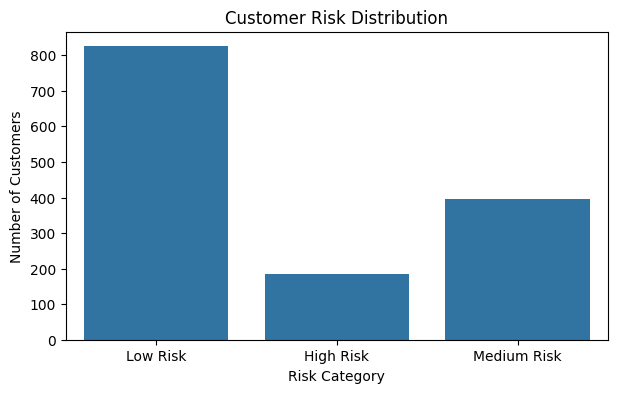

In [ ]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=dashboard_readable,
    x='Risk_Category'
)

plt.title('Customer Risk Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')

plt.show()

#Step 9.5 — Create the Final Dashboard File

In [ ]:
dashboard_readable.to_csv(
    'telco_churn_dashboard.csv',
    index=False
)

print("Dashboard dataset created successfully.")

Dashboard dataset created successfully.
